Run experiments and display graphs

In [2]:
# this block is added in case there is error like module not foundwhile importing like src,evaluation etc

import sys
from pathlib import Path

ROOT = Path.cwd()

# If the notebook starts inside experiments/, move to the project root.
if ROOT.name == "experiments":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("src exists:", (ROOT / "src").is_dir())

Project root: /home/Zoro/Projects/QuantForge
src exists: True


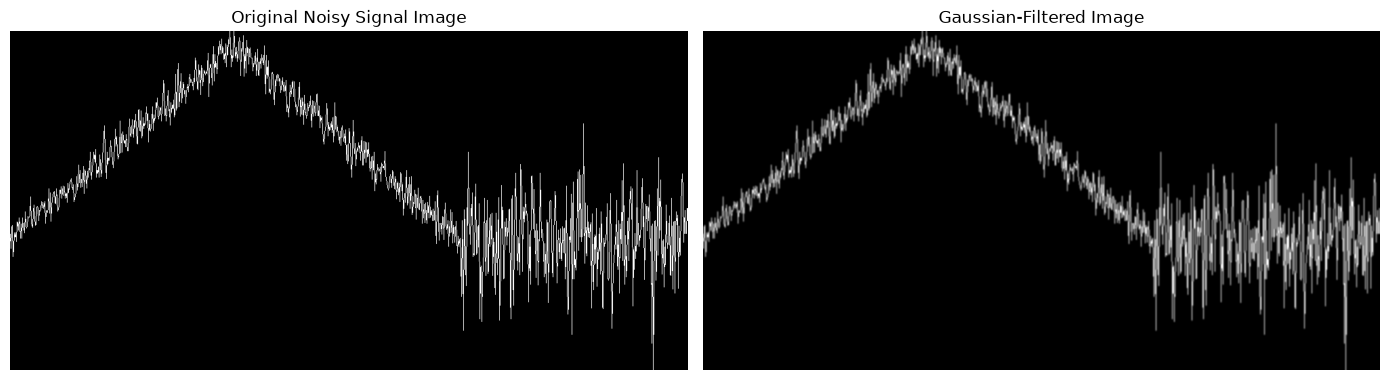

In [7]:
import matplotlib.pyplot as plt

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter

_, clean, noisy, _ = generate_signal()

original_image = signal_to_image(noisy)
filtered_image = apply_gaussian_filter(original_image)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original Noisy Signal Image")
axes[0].axis("off")

axes[1].imshow(filtered_image, cmap="gray")
axes[1].set_title("Gaussian-Filtered Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
import numpy as np
difference = cv2.absdiff(original_image, filtered_image)

print("Mean absolute pixel difference:", np.mean(difference))

Mean absolute pixel difference: 11.334926


In [10]:
filtered_3 = apply_gaussian_filter(original_image, kernel_size=3)
filtered_9 = apply_gaussian_filter(original_image, kernel_size=9)

print("Kernel 3 difference:", np.mean(cv2.absdiff(original_image, filtered_3)))
print("Kernel 9 difference:", np.mean(cv2.absdiff(original_image, filtered_9)))

Kernel 3 difference: 9.266338
Kernel 9 difference: 13.55723


In [12]:
import numpy as np
mse = np.mean((original_image.astype(float) - filtered_image.astype(float)) ** 2)

print("Image MSE:", mse)

Image MSE: 1238.394034


In [ ]:


import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.recover_signal import recover_signal

_, clean, noisy, _ = generate_signal()

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)

recovered = recover_signal(image, signal_min, signal_max)

print("Original signal length:", len(noisy))
print("Recovered signal length:", len(recovered))
print("First 5 original values:", noisy[:5])
print("First 5 recovered values:", recovered[:5])
print("MSE against clean signal:", np.mean((recovered - clean) ** 2))

Original signal length: 1000
Recovered signal length: 1000
First 5 original values: [100.45707562  98.52002384 101.28567679 101.65084707  97.39344722]
First 5 recovered values: [100.51116504  99.94616817 101.54699265 101.73532494  99.47533744]
MSE against clean signal: 7.030171539289175


In [ ]:
noisy_mse = np.mean((noisy - clean) ** 2)
recovered_mse = np.mean((recovered - clean) ** 2)

print(f"Noisy signal MSE:     {noisy_mse:.4f}")
print(f"Recovered signal MSE: {recovered_mse:.4f}")

if recovered_mse < noisy_mse:
    print("Image conversion improved the signal estimate.")
elif recovered_mse > noisy_mse:
    print("Image conversion made the signal estimate worse.")
else:
    print("Both have equal MSE.")

    #

Noisy signal MSE:     9.9651
Recovered signal MSE: 7.0302
Image conversion improved the signal estimate.


In [5]:
#experiment :gaussian filtering

from src.image_pipeline import apply_gaussian_filter

filtered_image = apply_gaussian_filter(image)

recovered_filtered = recover_signal(
    filtered_image,
    signal_min,
    signal_max
)

filtered_mse = np.mean((recovered_filtered - clean) ** 2)

print(f"Noisy signal MSE:             {noisy_mse:.4f}")
print(f"Unfiltered recovery MSE:      {recovered_mse:.4f}")
print(f"Gaussian-filtered recovery MSE: {filtered_mse:.4f}")

Noisy signal MSE:             9.9651
Unfiltered recovery MSE:      7.0302
Gaussian-filtered recovery MSE: 4.7392


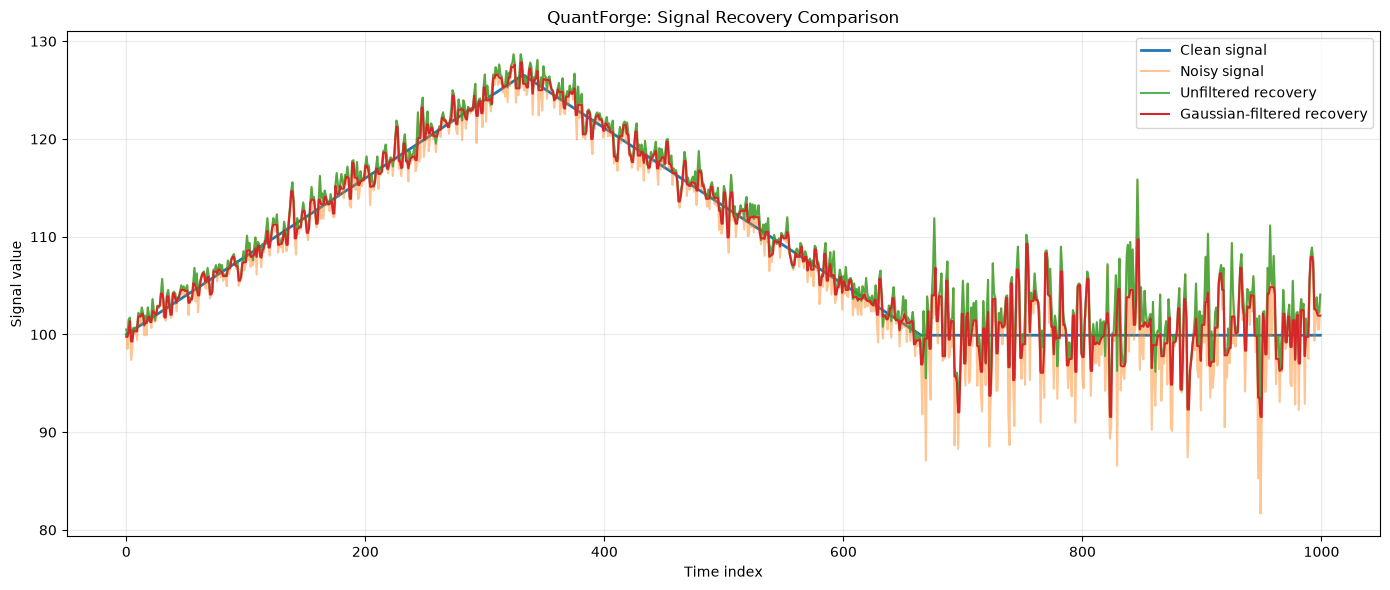

In [6]:
#visualising recovered signals
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(clean, label="Clean signal", linewidth=2)
plt.plot(noisy, label="Noisy signal", alpha=0.45)
plt.plot(recovered, label="Unfiltered recovery", alpha=0.8)
plt.plot(
    recovered_filtered,
    label="Gaussian-filtered recovery",
    linewidth=1.5
)

plt.title("QuantForge: Signal Recovery Comparison")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [7]:
#testing wether immprovement is consistent using one random seed

import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal

noisy_mses = []
recovered_mses = []
filtered_mses = []

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)

    recovered = recover_signal(image, signal_min, signal_max)

    filtered_image = apply_gaussian_filter(image)
    recovered_filtered = recover_signal(
        filtered_image, signal_min, signal_max
    )

    noisy_mses.append(np.mean((noisy - clean) ** 2))
    recovered_mses.append(np.mean((recovered - clean) ** 2))
    filtered_mses.append(np.mean((recovered_filtered - clean) ** 2))

print(f"Average noisy MSE:      {np.mean(noisy_mses):.4f}")
print(f"Average unfiltered MSE: {np.mean(recovered_mses):.4f}")
print(f"Average filtered MSE:   {np.mean(filtered_mses):.4f}")

wins = sum(f < n for f, n in zip(filtered_mses, noisy_mses))
print(f"Gaussian pipeline beats noisy input in {wins}/20 trials")

Average noisy MSE:      9.7735
Average unfiltered MSE: 7.1577
Average filtered MSE:   4.4697
Gaussian pipeline beats noisy input in 20/20 trials


In [ ]:
#comparing both methods on a small scale
from src.numerical_baselines import moving_average

numerical_recovered = moving_average(noisy, window_size=5)

numerical_mse = np.mean((numerical_recovered - clean) ** 2)

print(f"Noisy signal MSE:              {noisy_mse:.4f}")
print(f"Gaussian image pipeline MSE:   {filtered_mse:.4f}")
print(f"Numerical moving average MSE:  {numerical_mse:.4f}")

Noisy signal MSE:              9.9651
Gaussian image pipeline MSE:   4.7392
Numerical moving average MSE:  1.8059


In [9]:
#since it was successfull on a small scale next we run it across all 20 seeds
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

noisy_mses = []
image_mses = []
numerical_mses = []

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    # Image-processing approach
    image = signal_to_image(noisy)
    filtered_image = apply_gaussian_filter(image)
    recovered = recover_signal(
        filtered_image, signal_min, signal_max
    )

    # Direct numerical approach
    smoothed = moving_average(noisy, window_size=5)

    noisy_mses.append(np.mean((noisy - clean) ** 2))
    image_mses.append(np.mean((recovered - clean) ** 2))
    numerical_mses.append(np.mean((smoothed - clean) ** 2))

print(f"Average noisy MSE:      {np.mean(noisy_mses):.4f}")
print(f"Average image MSE:      {np.mean(image_mses):.4f}")
print(f"Average numerical MSE:  {np.mean(numerical_mses):.4f}")

image_wins = sum(
    i < n for i, n in zip(image_mses, numerical_mses)
)
numerical_wins = sum(
    n < i for i, n in zip(image_mses, numerical_mses)
)

print(f"Image pipeline wins: {image_wins}/20")
print(f"Numerical method wins: {numerical_wins}/20")

Average noisy MSE:      9.7735
Average image MSE:      4.4697
Average numerical MSE:  2.0028
Image pipeline wins: 0/20
Numerical method wins: 20/20


In [10]:
#testing 7 settings across the same 20 seeds to find the best MSE
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

sizes = [3, 5, 7, 9, 11, 15, 21]
seeds = range(20)

image_results = {}
numerical_results = {}

# Test numerical smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)
        smoothed = moving_average(noisy, window_size=size)
        errors.append(np.mean((smoothed - clean) ** 2))

    numerical_results[size] = np.mean(errors)

# Test image smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered_image = apply_gaussian_filter(
            image, kernel_size=size
        )

        recovered = recover_signal(
            filtered_image, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    image_results[size] = np.mean(errors)

print("NUMERICAL MOVING AVERAGE")
for size, mse in numerical_results.items():
    print(f"Window {size:2}: MSE = {mse:.4f}")

print("\nGAUSSIAN IMAGE PIPELINE")
for size, mse in image_results.items():
    print(f"Kernel {size:2}: MSE = {mse:.4f}")

best_num = min(numerical_results, key=numerical_results.get)
best_img = min(image_results, key=image_results.get)

print(f"\nBest numerical window: {best_num}, "
      f"MSE = {numerical_results[best_num]:.4f}")
print(f"Best Gaussian kernel: {best_img}, "
      f"MSE = {image_results[best_img]:.4f}")

NUMERICAL MOVING AVERAGE
Window  3: MSE = 3.3162
Window  5: MSE = 2.0028
Window  7: MSE = 1.4383
Window  9: MSE = 1.1271
Window 11: MSE = 0.9295
Window 15: MSE = 0.6970
Window 21: MSE = 0.5112

GAUSSIAN IMAGE PIPELINE
Kernel  3: MSE = 4.9692
Kernel  5: MSE = 4.4697
Kernel  7: MSE = 3.7056
Kernel  9: MSE = 3.1452
Kernel 11: MSE = 2.6516
Kernel 15: MSE = 2.0962
Kernel 21: MSE = 1.6534

Best numerical window: 21, MSE = 0.5112
Best Gaussian kernel: 21, MSE = 1.6534


In [11]:
#running the above test for larger sizes
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

sizes = [21, 31, 41, 51, 71, 101]
seeds = range(20)

image_results = {}
numerical_results = {}

# Test numerical smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)
        smoothed = moving_average(noisy, window_size=size)
        errors.append(np.mean((smoothed - clean) ** 2))

    numerical_results[size] = np.mean(errors)

# Test image smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered_image = apply_gaussian_filter(
            image, kernel_size=size
        )

        recovered = recover_signal(
            filtered_image, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    image_results[size] = np.mean(errors)

print("NUMERICAL MOVING AVERAGE")
for size, mse in numerical_results.items():
    print(f"Window {size:2}: MSE = {mse:.4f}")

print("\nGAUSSIAN IMAGE PIPELINE")
for size, mse in image_results.items():
    print(f"Kernel {size:2}: MSE = {mse:.4f}")

best_num = min(numerical_results, key=numerical_results.get)
best_img = min(image_results, key=image_results.get)

print(f"\nBest numerical window: {best_num}, "
      f"MSE = {numerical_results[best_num]:.4f}")
print(f"Best Gaussian kernel: {best_img}, "
      f"MSE = {image_results[best_img]:.4f}")

NUMERICAL MOVING AVERAGE
Window 21: MSE = 0.5112
Window 31: MSE = 0.3678
Window 41: MSE = 0.3077
Window 51: MSE = 0.2828
Window 71: MSE = 0.2796
Window 101: MSE = 0.3515

GAUSSIAN IMAGE PIPELINE
Kernel 21: MSE = 1.6534
Kernel 31: MSE = 1.2781
Kernel 41: MSE = 1.0012
Kernel 51: MSE = 0.8088
Kernel 71: MSE = 0.5708
Kernel 101: MSE = 0.4107

Best numerical window: 71, MSE = 0.2796
Best Gaussian kernel: 101, MSE = 0.4107


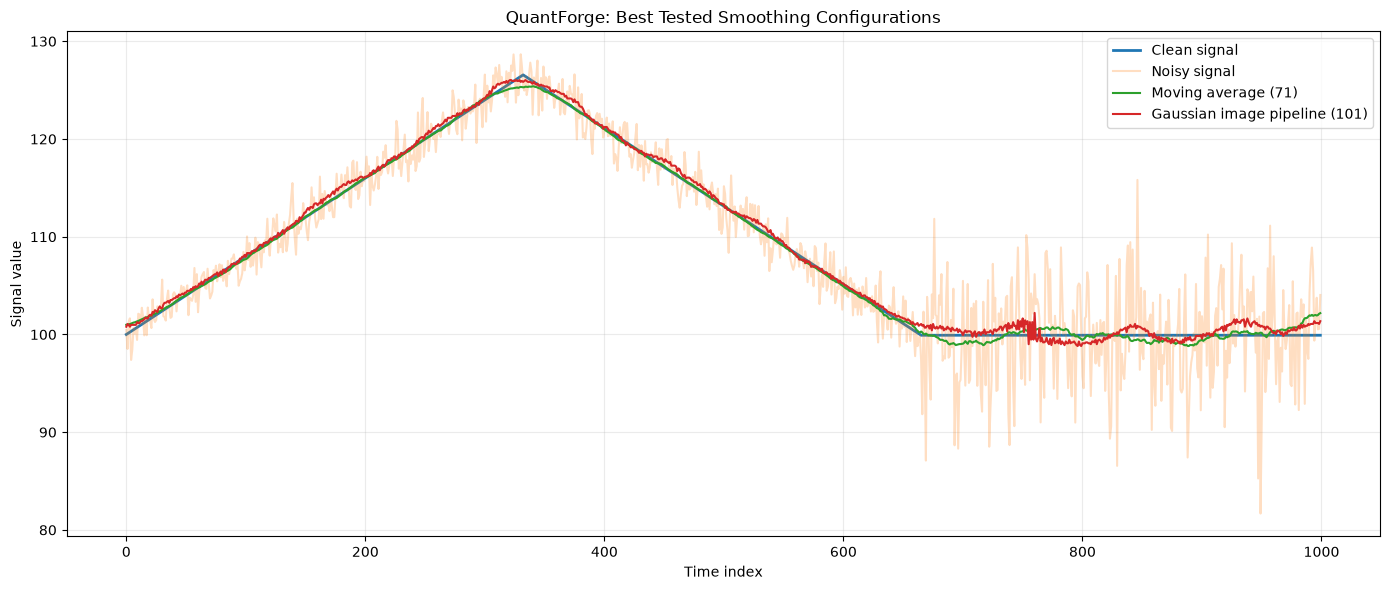

In [12]:
#inspecting the smoothed  signals
import matplotlib.pyplot as plt

_, clean, noisy, _ = generate_signal(seed=42)

numerical_71 = moving_average(noisy, window_size=71)

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)
filtered_101 = apply_gaussian_filter(image, kernel_size=101)

image_101 = recover_signal(
    filtered_101, signal_min, signal_max
)

plt.figure(figsize=(14, 6))
plt.plot(clean, label="Clean signal", linewidth=2)
plt.plot(noisy, label="Noisy signal", alpha=0.25)
plt.plot(numerical_71, label="Moving average (71)")
plt.plot(image_101, label="Gaussian image pipeline (101)")

plt.title("QuantForge: Best Tested Smoothing Configurations")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
#measuring transition error
# Examine a region around each regime transition.
transition_points = [333, 666]
radius = 25

for point in transition_points:
    start = max(0, point - radius)
    end = min(len(clean), point + radius + 1)

    clean_region = clean[start:end]
    numerical_region = numerical_71[start:end]
    image_region = image_101[start:end]

    numerical_mse = np.mean((numerical_region - clean_region) ** 2)
    image_mse = np.mean((image_region - clean_region) ** 2)

    print(f"\nTransition near index {point}:")
    print(f"Numerical moving average MSE: {numerical_mse:.4f}")
    print(f"Gaussian image pipeline MSE:  {image_mse:.4f}")


Transition near index 333:
Numerical moving average MSE: 0.3639
Gaussian image pipeline MSE:  0.1564

Transition near index 666:
Numerical moving average MSE: 0.1552
Gaussian image pipeline MSE:  0.5442


In [14]:
#testing across all 20 seeds
transition_errors = {
    "numerical_333": [],
    "image_333": [],
    "numerical_666": [],
    "image_666": [],
}

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    numerical = moving_average(noisy, window_size=71)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)
    filtered = apply_gaussian_filter(image, kernel_size=101)
    recovered_image = recover_signal(filtered, signal_min, signal_max)

    for point in [333, 666]:
        start = point - 25
        end = point + 26

        clean_region = clean[start:end]
        numerical_mse = np.mean(
            (numerical[start:end] - clean_region) ** 2
        )
        image_mse = np.mean(
            (recovered_image[start:end] - clean_region) ** 2
        )

        prefix = "333" if point == 333 else "666"
        transition_errors[f"numerical_{prefix}"].append(numerical_mse)
        transition_errors[f"image_{prefix}"].append(image_mse)

for point in [333, 666]:
    print(f"\nTransition near index {point}:")
    print(
        "Moving average mean MSE:",
        f"{np.mean(transition_errors[f'numerical_{point}']):.4f}"
    )
    print(
        "Image pipeline mean MSE:",
        f"{np.mean(transition_errors[f'image_{point}']):.4f}"
    )


Transition near index 333:
Moving average mean MSE: 0.6171
Image pipeline mean MSE: 0.1794

Transition near index 666:
Moving average mean MSE: 0.2756
Image pipeline mean MSE: 0.4521


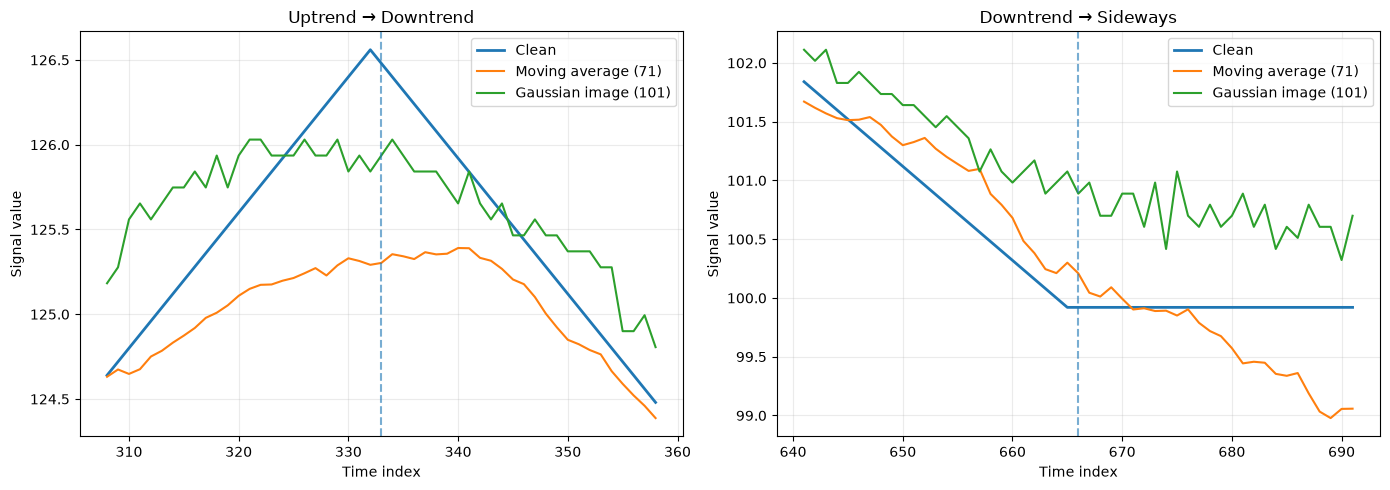

In [15]:
#visualise the transition regions

import matplotlib.pyplot as plt

_, clean, noisy, _ = generate_signal(seed=42)
numerical = moving_average(noisy, window_size=71)

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)
filtered = apply_gaussian_filter(image, kernel_size=101)
recovered_image = recover_signal(filtered, signal_min, signal_max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, point, title in zip(
    axes,
    [333, 666],
    ["Uptrend → Downtrend", "Downtrend → Sideways"]
):
    start, end = point - 25, point + 26
    x = np.arange(start, end)

    ax.plot(x, clean[start:end], label="Clean", linewidth=2)
    ax.plot(x, numerical[start:end], label="Moving average (71)")
    ax.plot(x, recovered_image[start:end], label="Gaussian image (101)")
    ax.axvline(point, linestyle="--", alpha=0.6)

    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Signal value")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [4]:
import time
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average
seeds = range(20)

numerical_times = []
image_times = []

numerical_errors = []
image_errors = []

for seed in seeds:
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    # Numerical pipeline timing
    start = time.perf_counter()

    numerical = moving_average(noisy, window_size=71)

    numerical_times.append(time.perf_counter() - start)

    numerical_errors.append(
        np.mean((numerical - clean) ** 2)
    )

    # Image pipeline timing
    start = time.perf_counter()

    image = signal_to_image(noisy)
    filtered = apply_gaussian_filter(image, kernel_size=101)

    recovered = recover_signal(
        filtered, signal_min, signal_max
    )

    image_times.append(time.perf_counter() - start)

    image_errors.append(
        np.mean((recovered - clean) ** 2)
    )

print("BENCHMARK RESULTS")
print("-" * 40)

print(f"Numerical average MSE: {np.mean(numerical_errors):.4f}")
print(f"Image average MSE:     {np.mean(image_errors):.4f}")

print(f"\nNumerical average time: {np.mean(numerical_times)*1000:.4f} ms")
print(f"Image average time:     {np.mean(image_times)*1000:.4f} ms")

BENCHMARK RESULTS
----------------------------------------
Numerical average MSE: 0.2796
Image average MSE:     0.4107

Numerical average time: 0.0656 ms
Image average time:     8.6310 ms


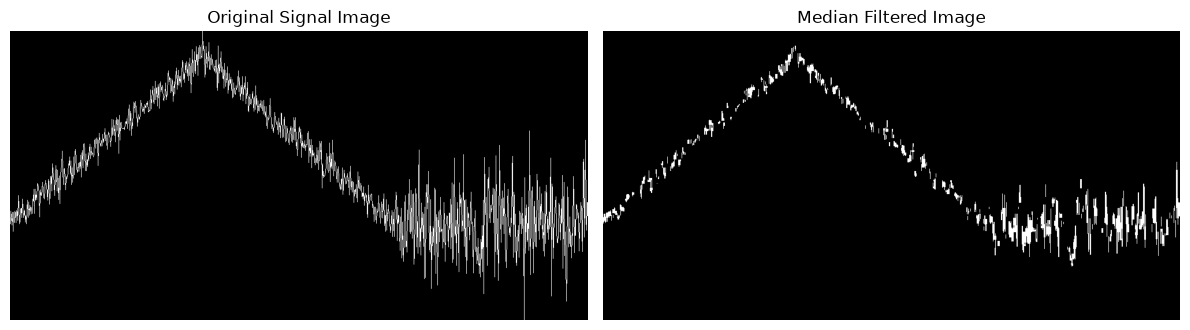

In [12]:
from src.image_pipeline import apply_median_filter
import matplotlib.pyplot as plt

median_image = apply_median_filter(image, kernel_size=5)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Signal Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median_image, cmap="gray")
plt.title("Median Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#comparing gaussian vs median filtering

gaussian_mses = []
median_mses = []

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)

    # Gaussian filtering
    gaussian_image = apply_gaussian_filter(
        image, kernel_size=5
    )
    gaussian_recovered = recover_signal(
        gaussian_image, signal_min, signal_max
    )

    # Median filtering
    median_image = apply_median_filter(
        image, kernel_size=5
    )
    median_recovered = recover_signal(
        median_image, signal_min, signal_max
    )

    gaussian_mses.append(
        np.mean((gaussian_recovered - clean) ** 2)
    )

    median_mses.append(
        np.mean((median_recovered - clean) ** 2)
    )

print(f"Gaussian average MSE: {np.mean(gaussian_mses):.4f}")
print(f"Median average MSE:   {np.mean(median_mses):.4f}")

print(
    "Gaussian wins:",
    sum(g < m for g, m in zip(gaussian_mses, median_mses)),
    "/20"
)

print(
    "Median wins:",
    sum(m < g for g, m in zip(gaussian_mses, median_mses)),
    "/20"
)

Gaussian average MSE: 4.4697
Median average MSE:   126.3146
Gaussian wins: 20 /20
Median wins: 0 /20


In [ ]:
#checking the reason for such a huge difference between avg MSEs
print("Original image:")
print("Nonzero pixels:", np.count_nonzero(image))

print("\nMedian-filtered image:")
print("Nonzero pixels:", np.count_nonzero(median_image))

print("\nOriginal nonempty columns:",
      np.count_nonzero(np.any(image > 0, axis=0)))

print("Median nonempty columns:",
      np.count_nonzero(np.any(median_image > 0, axis=0)))

Original image:
Nonzero pixels: 23481

Median-filtered image:
Nonzero pixels: 11831

Original nonempty columns: 1000
Median nonempty columns: 705


In [16]:
import importlib
import src.signal_to_image as signal_module

importlib.reload(signal_module)

from src.signal_to_image import signal_to_image

In [ ]:
#improved median avg mse after changing thickness to 3 (basically huge diff for the base img /vall we have for testing)

image = signal_to_image(noisy)
median_image = apply_median_filter(image, kernel_size=5)

median_recovered = recover_signal(
    median_image, signal_min, signal_max
)

print(
    "Median MSE:",
    np.mean((median_recovered - clean) ** 2)
)

print(
    "Nonempty columns:",
    np.count_nonzero(np.any(median_image > 0, axis=0))
)

Median MSE: 17.19183700190886
Nonempty columns: 1000


In [ ]:
#comparing median kernels 3,5,7 using new thickness 3

median_results = {}

for kernel in [3, 5, 7]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)  # thickness 3

        filtered = apply_median_filter(
            image, kernel_size=kernel
        )

        recovered = recover_signal(
            filtered, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    median_results[kernel] = np.mean(errors)

print("MEDIAN FILTER — THICKNESS 3")

for kernel, mse in median_results.items():
    print(f"Kernel {kernel}: Average MSE = {mse:.4f}")

MEDIAN FILTER — THICKNESS 3
Kernel 3: Average MSE = 18.6387
Kernel 5: Average MSE = 18.7594
Kernel 7: Average MSE = 18.9456


In [ ]:
#running gaussian filtering with thickness 3 for fair comparison
gaussian_results = {}

for kernel in [3, 5, 7, 9, 11]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)  # thickness 3

        filtered = apply_gaussian_filter(
            image, kernel_size=kernel
        )

        recovered = recover_signal(
            filtered, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    gaussian_results[kernel] = np.mean(errors)

print("GAUSSIAN FILTER — THICKNESS 3")

for kernel, mse in gaussian_results.items():
    print(f"Kernel {kernel}: Average MSE = {mse:.4f}")

GAUSSIAN FILTER — THICKNESS 3
Kernel 3: Average MSE = 13.5994
Kernel 5: Average MSE = 9.0691
Kernel 7: Average MSE = 5.9784
Kernel 9: Average MSE = 4.5260
Kernel 11: Average MSE = 3.5910


In [ ]:
#extending gaussian sweep to higher kernels
for kernel in [15, 21, 31, 41, 51]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered = apply_gaussian_filter(image, kernel_size=kernel)

        recovered = recover_signal(filtered, signal_min, signal_max)

        errors.append(np.mean((recovered - clean) ** 2))

    print(f"Kernel {kernel}: Average MSE = {np.mean(errors):.4f}")

Kernel 15: Average MSE = 2.4137
Kernel 21: Average MSE = 1.6754
Kernel 31: Average MSE = 1.0426
Kernel 41: Average MSE = 0.7603
Kernel 51: Average MSE = 0.6240


In [ ]:
#further extending kernels to check if there is improvement
for kernel in [61, 71, 81, 101, 121]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered = apply_gaussian_filter(image, kernel_size=kernel)

        recovered = recover_signal(filtered, signal_min, signal_max)

        errors.append(np.mean((recovered - clean) ** 2))

    print(f"Kernel {kernel}: Average MSE = {np.mean(errors):.4f}")

Kernel 61: Average MSE = 0.5362
Kernel 71: Average MSE = 0.4785
Kernel 81: Average MSE = 0.4314
Kernel 101: Average MSE = 0.3665
Kernel 121: Average MSE = 0.3263


In [22]:
#extending again
for kernel in [151, 181, 201, 251, 301]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered = apply_gaussian_filter(image, kernel_size=kernel)

        recovered = recover_signal(filtered, signal_min, signal_max)

        errors.append(np.mean((recovered - clean) ** 2))

    print(f"Kernel {kernel}: Average MSE = {np.mean(errors):.4f}")

Kernel 151: Average MSE = 0.3098
Kernel 181: Average MSE = 0.3331
Kernel 201: Average MSE = 0.3640
Kernel 251: Average MSE = 0.5464
Kernel 301: Average MSE = 0.9343


we can see that the value starts worsening after 201 i.e. value increases

In [23]:
#comparing against numerical moving average
numerical_results = {}

for window in [51, 71, 101, 121, 151, 181, 201]:
    errors = []

    for seed in range(20):
        _, clean, noisy, _ = generate_signal(seed=seed)

        recovered = moving_average(noisy, window_size=window)

        errors.append(np.mean((recovered - clean) ** 2))

    numerical_results[window] = np.mean(errors)

print("NUMERICAL MOVING AVERAGE")
for window, mse in numerical_results.items():
    print(f"Window {window}: Average MSE = {mse:.4f}")


NUMERICAL MOVING AVERAGE
Window 51: Average MSE = 0.2828
Window 71: Average MSE = 0.2796
Window 101: Average MSE = 0.3515
Window 121: Average MSE = 0.4399
Window 151: Average MSE = 0.6427
Window 181: Average MSE = 0.9430
Window 201: Average MSE = 1.2048


In [ ]:
#checking around 2 regime transitions before conclusion i.e. indices 333 and 666
transition_results = {
    "gaussian": {333: [], 666: []},
    "numerical": {333: [], 666: []}
}

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    # Gaussian image pipeline
    image = signal_to_image(noisy)
    filtered = apply_gaussian_filter(image, kernel_size=151)
    gaussian_recovered = recover_signal(
        filtered, signal_min, signal_max
    )

    # Numerical baseline
    numerical_recovered = moving_average(
        noisy, window_size=71
    )

    for boundary in [333, 666]:
        start = boundary - 25
        end = boundary + 26

        gaussian_mse = np.mean(
            (gaussian_recovered[start:end] - clean[start:end]) ** 2
        )

        numerical_mse = np.mean(
            (numerical_recovered[start:end] - clean[start:end]) ** 2
        )

        transition_results["gaussian"][boundary].append(gaussian_mse)
        transition_results["numerical"][boundary].append(numerical_mse)

for boundary in [333, 666]:
    print(f"\nTRANSITION: {boundary}")

    print(
        "Gaussian:",
        np.mean(transition_results["gaussian"][boundary])
    )

    print(
        "Numerical:",
        np.mean(transition_results["numerical"][boundary])
    )


TRANSITION: 333
Gaussian: 0.29876407059793986
Numerical: 0.6171312477534724

TRANSITION: 666
Gaussian: 0.7575523382300199
Numerical: 0.2756072644023181


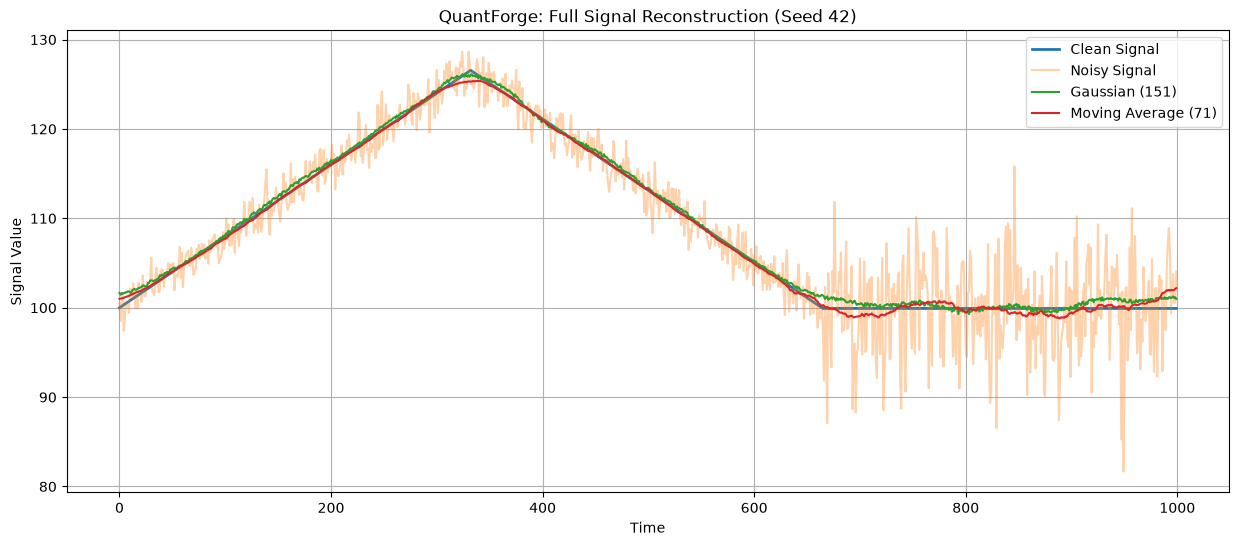

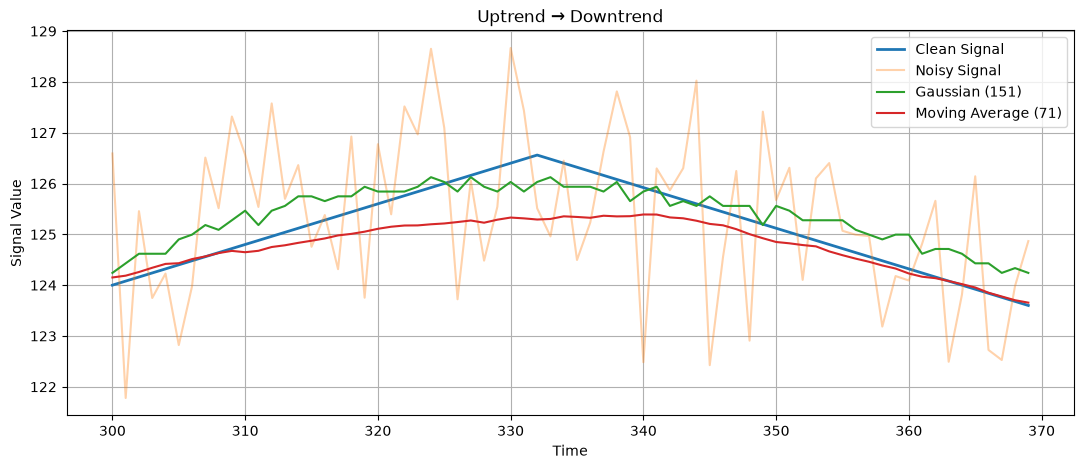

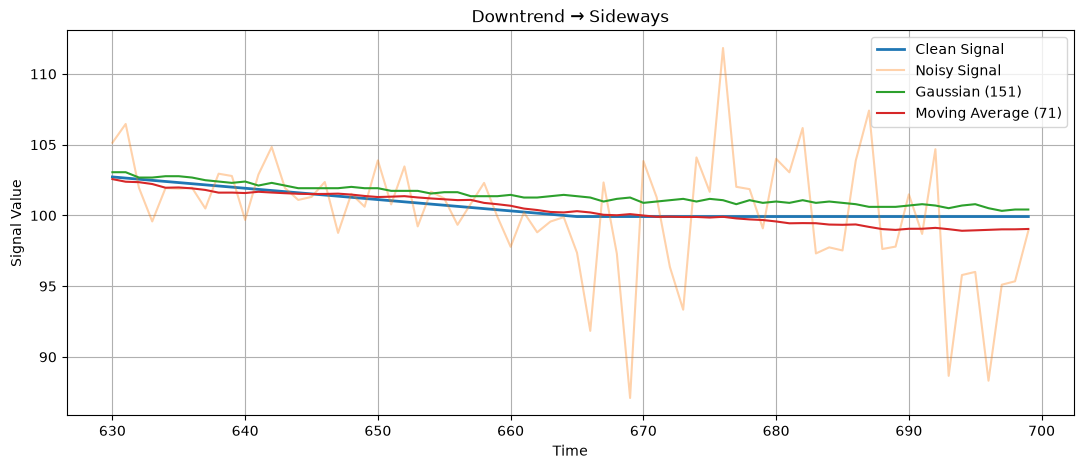

In [ ]:
#plotting to compare noisy,clean,gaussian recoverd and numerically recovered signal

import matplotlib.pyplot as plt

seed = 42

_, clean, noisy, _ = generate_signal(seed=seed)

signal_min = np.min(noisy)
signal_max = np.max(noisy)

# Gaussian pipeline
image = signal_to_image(noisy)
gaussian_filtered = apply_gaussian_filter(image, kernel_size=151)
gaussian_recovered = recover_signal(
    gaussian_filtered, signal_min, signal_max
)

# Numerical baseline
numerical_recovered = moving_average(noisy, window_size=71)

# Full signal
plt.figure(figsize=(15, 6))
plt.plot(clean, label="Clean Signal", linewidth=2)
plt.plot(noisy, label="Noisy Signal", alpha=0.35)
plt.plot(gaussian_recovered, label="Gaussian (151)")
plt.plot(numerical_recovered, label="Moving Average (71)")
plt.title("QuantForge: Full Signal Reconstruction (Seed 42)")
plt.xlabel("Time")
plt.ylabel("Signal Value")
plt.legend()
plt.grid()
plt.show()

# Zoom into both transitions
for start, end, title in [
    (300, 370, "Uptrend → Downtrend"),
    (630, 700, "Downtrend → Sideways")
]:
    plt.figure(figsize=(13, 5))
    plt.plot(
        range(start, end), clean[start:end],
        label="Clean Signal", linewidth=2
    )
    plt.plot(
        range(start, end), noisy[start:end],
        label="Noisy Signal", alpha=0.35
    )
    plt.plot(
        range(start, end), gaussian_recovered[start:end],
        label="Gaussian (151)"
    )
    plt.plot(
        range(start, end), numerical_recovered[start:end],
        label="Moving Average (71)"
    )

    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Signal Value")
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
#evaluating each regime separately(uptrend,downtrend and sidetrend)
regime_results = {
    "gaussian": {},
    "numerical": {}
}

for seed in range(20):
    _, clean, noisy, regimes = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)

    gaussian_filtered = apply_gaussian_filter(
        image, kernel_size=151
    )

    gaussian_recovered = recover_signal(
        gaussian_filtered, signal_min, signal_max
    )

    numerical_recovered = moving_average(
        noisy, window_size=71
    )

    for regime in ["uptrend", "downtrend", "sideways"]:
        mask = regimes == regime

        gaussian_mse = np.mean(
            (gaussian_recovered[mask] - clean[mask]) ** 2
        )

        numerical_mse = np.mean(
            (numerical_recovered[mask] - clean[mask]) ** 2
        )

        regime_results["gaussian"].setdefault(regime, []).append(
            gaussian_mse
        )

        regime_results["numerical"].setdefault(regime, []).append(
            numerical_mse
        )

for regime in ["uptrend", "downtrend", "sideways"]:
    print(f"\n{regime.upper()}")

    print(
        f"Gaussian: {np.mean(regime_results['gaussian'][regime]):.4f}"
    )

    print(
        f"Numerical: {np.mean(regime_results['numerical'][regime]):.4f}"
    )


UPTREND
Gaussian: 0.2132
Numerical: 0.1136

DOWNTREND
Gaussian: 0.2092
Numerical: 0.0905

SIDEWAYS
Gaussian: 0.5063
Numerical: 0.6338


In [ ]:
#reloading module after adding parameter and making changes

import importlib
import src.generate_signals as signal_module

importlib.reload(signal_module)

generate_signal = signal_module.generate_signal

In [34]:
noise_levels = [1.5, 3.0, 5.0, 7.0, 10.0]

for noise_std in noise_levels:
    gaussian_errors = []
    numerical_errors = []

    for seed in range(20):
        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        # Gaussian image pipeline
        image = signal_to_image(noisy)
        filtered = apply_gaussian_filter(image, kernel_size=151)

        gaussian_recovered = recover_signal(
            filtered, np.min(noisy), np.max(noisy)
        )

        # Numerical baseline
        numerical_recovered = moving_average(
            noisy, window_size=71
        )

        gaussian_errors.append(
            np.mean((gaussian_recovered[mask] - clean[mask]) ** 2)
        )

        numerical_errors.append(
            np.mean((numerical_recovered[mask] - clean[mask]) ** 2)
        )

    print(f"\nSideways noise STD: {noise_std}")
    print(f"Gaussian MSE: {np.mean(gaussian_errors):.4f}")
    print(f"Numerical MSE: {np.mean(numerical_errors):.4f}")



Sideways noise STD: 1.5
Gaussian MSE: 0.0659
Numerical MSE: 0.0661

Sideways noise STD: 3.0
Gaussian MSE: 0.1891
Numerical MSE: 0.2345

Sideways noise STD: 5.0
Gaussian MSE: 0.5063
Numerical MSE: 0.6338

Sideways noise STD: 7.0
Gaussian MSE: 1.0341
Numerical MSE: 1.2328

Sideways noise STD: 10.0
Gaussian MSE: 2.2232
Numerical MSE: 2.5058


In [ ]:
#adding kernels

noise_levels = [1.5, 3.0, 5.0, 7.0, 10.0]
kernels = [51, 71, 101, 121, 151, 181, 201]

optimization_results = {}

for noise_std in noise_levels:

    kernel_errors = {k: [] for k in kernels}
    numerical_errors = []

    for seed in range(20):

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)

        for kernel in kernels:
            filtered = apply_gaussian_filter(
                image, kernel_size=kernel
            )

            recovered = recover_signal(
                filtered, signal_min, signal_max
            )

            mse = np.mean(
                (recovered[mask] - clean[mask]) ** 2
            )

            kernel_errors[kernel].append(mse)

        numerical = moving_average(noisy, window_size=71)

        numerical_errors.append(
            np.mean((numerical[mask] - clean[mask]) ** 2)
        )

    average_errors = {
        k: np.mean(errors)
        for k, errors in kernel_errors.items()
    }

    best_kernel = min(average_errors, key=average_errors.get)

    optimization_results[noise_std] = {
        "best_kernel": best_kernel,
        "gaussian_mse": average_errors[best_kernel],
        "numerical_mse": np.mean(numerical_errors)
    }

    print(f"\nNoise STD: {noise_std}")
    print(f"Best Gaussian kernel: {best_kernel}")
    print(f"Gaussian MSE: {average_errors[best_kernel]:.4f}")
    print(f"Numerical MSE: {np.mean(numerical_errors):.4f}")


Noise STD: 1.5
Best Gaussian kernel: 121
Gaussian MSE: 0.0624
Numerical MSE: 0.0661

Noise STD: 3.0
Best Gaussian kernel: 181
Gaussian MSE: 0.1791
Numerical MSE: 0.2345

Noise STD: 5.0
Best Gaussian kernel: 201
Gaussian MSE: 0.4213
Numerical MSE: 0.6338

Noise STD: 7.0
Best Gaussian kernel: 201
Gaussian MSE: 0.7894
Numerical MSE: 1.2328

Noise STD: 10.0
Best Gaussian kernel: 201
Gaussian MSE: 1.6220
Numerical MSE: 2.5058


In [ ]:
#adding windows
noise_levels = [1.5, 3.0, 5.0, 7.0, 10.0]

kernels = [51, 71, 101, 121, 151, 181, 201]
windows = [31, 51, 71, 101, 121, 151, 181, 201, 251]

optimization_results = {}

for noise_std in noise_levels:

    kernel_errors = {k: [] for k in kernels}
    window_errors = {w: [] for w in windows}

    for seed in range(20):

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)

        # Gaussian configurations
        for kernel in kernels:
            filtered = apply_gaussian_filter(
                image, kernel_size=kernel
            )

            recovered = recover_signal(
                filtered, signal_min, signal_max
            )

            mse = np.mean(
                (recovered[mask] - clean[mask]) ** 2
            )

            kernel_errors[kernel].append(mse)

        # Numerical configurations
        for window in windows:
            recovered = moving_average(
                noisy, window_size=window
            )

            mse = np.mean(
                (recovered[mask] - clean[mask]) ** 2
            )

            window_errors[window].append(mse)

    gaussian_avg = {
        k: np.mean(v) for k, v in kernel_errors.items()
    }

    numerical_avg = {
        w: np.mean(v) for w, v in window_errors.items()
    }

    best_kernel = min(gaussian_avg, key=gaussian_avg.get)
    best_window = min(numerical_avg, key=numerical_avg.get)

    optimization_results[noise_std] = {
        "gaussian_kernel": best_kernel,
        "gaussian_mse": gaussian_avg[best_kernel],
        "numerical_window": best_window,
        "numerical_mse": numerical_avg[best_window]
    }

    print(f"\nNoise STD: {noise_std}")
    print(
        f"Gaussian: kernel={best_kernel}, "
        f"MSE={gaussian_avg[best_kernel]:.4f}"
    )
    print(
        f"Numerical: window={best_window}, "
        f"MSE={numerical_avg[best_window]:.4f}"
    )


Noise STD: 1.5
Gaussian: kernel=121, MSE=0.0624
Numerical: window=51, MSE=0.0661

Noise STD: 3.0
Gaussian: kernel=181, MSE=0.1791
Numerical: window=71, MSE=0.2345

Noise STD: 5.0
Gaussian: kernel=201, MSE=0.4213
Numerical: window=71, MSE=0.6338

Noise STD: 7.0
Gaussian: kernel=201, MSE=0.7894
Numerical: window=71, MSE=1.2328

Noise STD: 10.0
Gaussian: kernel=201, MSE=1.6220
Numerical: window=71, MSE=2.5058


LOCKING IN THE EVALUATION METHADOLOGY (USING 50 training seeds and 50 unseen seeds)

In [41]:
#training phase(selecting best gaussian kernel and numerical window using training data only)
import numpy as np

train_seeds = range(50)
test_seeds = range(100, 150)

noise_levels = [1.5, 3.0, 5.0, 7.0, 10.0]

kernels = [51, 71, 101, 121, 151, 181, 201]
windows = [31, 51, 71, 101, 121, 151, 181, 201, 251]

trained_models = {}

for noise_std in noise_levels:

    gaussian_errors = {k: [] for k in kernels}
    numerical_errors = {w: [] for w in windows}

    for seed in train_seeds:

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)

        for kernel in kernels:
            filtered = apply_gaussian_filter(
                image, kernel_size=kernel
            )

            recovered = recover_signal(
                filtered, signal_min, signal_max
            )

            gaussian_errors[kernel].append(
                np.mean((recovered[mask] - clean[mask]) ** 2)
            )

        for window in windows:
            recovered = moving_average(
                noisy, window_size=window
            )

            numerical_errors[window].append(
                np.mean((recovered[mask] - clean[mask]) ** 2)
            )

    gaussian_avg = {
        k: np.mean(v) for k, v in gaussian_errors.items()
    }

    numerical_avg = {
        w: np.mean(v) for w, v in numerical_errors.items()
    }

    best_kernel = min(gaussian_avg, key=gaussian_avg.get)
    best_window = min(numerical_avg, key=numerical_avg.get)

    trained_models[noise_std] = {
        "kernel": best_kernel,
        "window": best_window
    }

    print(f"\nNoise STD: {noise_std}")
    print(f"Best Gaussian kernel: {best_kernel}")
    print(f"Best numerical window: {best_window}")


Noise STD: 1.5
Best Gaussian kernel: 121
Best numerical window: 51

Noise STD: 3.0
Best Gaussian kernel: 181
Best numerical window: 71

Noise STD: 5.0
Best Gaussian kernel: 201
Best numerical window: 71

Noise STD: 7.0
Best Gaussian kernel: 201
Best numerical window: 71

Noise STD: 10.0
Best Gaussian kernel: 201
Best numerical window: 71


In [ ]:
#running on seeds 100-149 and parameters selected during training
test_results = {}

for noise_std in noise_levels:

    kernel = trained_models[noise_std]["kernel"]
    window = trained_models[noise_std]["window"]

    gaussian_errors = []
    numerical_errors = []

    for seed in test_seeds:

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        # Gaussian pipeline
        image = signal_to_image(noisy)

        filtered = apply_gaussian_filter(
            image, kernel_size=kernel
        )

        gaussian_recovered = recover_signal(
            filtered, np.min(noisy), np.max(noisy)
        )

        # Numerical baseline
        numerical_recovered = moving_average(
            noisy, window_size=window
        )

        gaussian_errors.append(
            np.mean(
                (gaussian_recovered[mask] - clean[mask]) ** 2
            )
        )

        numerical_errors.append(
            np.mean(
                (numerical_recovered[mask] - clean[mask]) ** 2
            )
        )

    test_results[noise_std] = {
        "gaussian_mse": np.mean(gaussian_errors),
        "numerical_mse": np.mean(numerical_errors),
        "gaussian_std": np.std(gaussian_errors, ddof=1),
        "numerical_std": np.std(numerical_errors, ddof=1)
    }

    print(f"\nNoise STD: {noise_std}")
    print(f"Gaussian MSE: {np.mean(gaussian_errors):.4f}")
    print(f"Numerical MSE: {np.mean(numerical_errors):.4f}")


Noise STD: 1.5
Gaussian MSE: 0.0697
Numerical MSE: 0.0590

Noise STD: 3.0
Gaussian MSE: 0.2117
Numerical MSE: 0.1982

Noise STD: 5.0
Gaussian MSE: 0.5018
Numerical MSE: 0.5298

Noise STD: 7.0
Gaussian MSE: 0.9430
Numerical MSE: 1.0270

Noise STD: 10.0
Gaussian MSE: 1.9071
Numerical MSE: 2.0835


Gaussian filtering generalizes well at higher noise levels, but the numerical method performs better at lower noise levels.

In [43]:
#paired statistical testing
from scipy.stats import wilcoxon
import numpy as np

paired_results = {}

for noise_std in noise_levels:

    kernel = trained_models[noise_std]["kernel"]
    window = trained_models[noise_std]["window"]

    gaussian_errors = []
    numerical_errors = []

    for seed in test_seeds:

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        image = signal_to_image(noisy)

        filtered = apply_gaussian_filter(
            image, kernel_size=kernel
        )

        gaussian_recovered = recover_signal(
            filtered, np.min(noisy), np.max(noisy)
        )

        numerical_recovered = moving_average(
            noisy, window_size=window
        )

        gaussian_errors.append(
            np.mean(
                (gaussian_recovered[mask] - clean[mask]) ** 2
            )
        )

        numerical_errors.append(
            np.mean(
                (numerical_recovered[mask] - clean[mask]) ** 2
            )
        )

    gaussian_errors = np.array(gaussian_errors)
    numerical_errors = np.array(numerical_errors)

    differences = gaussian_errors - numerical_errors

    statistic, p_value = wilcoxon(
        gaussian_errors,
        numerical_errors,
        alternative="two-sided"
    )

    paired_results[noise_std] = {
        "gaussian_mean": np.mean(gaussian_errors),
        "numerical_mean": np.mean(numerical_errors),
        "mean_difference": np.mean(differences),
        "p_value": p_value
    }

    print(f"\nNoise STD: {noise_std}")
    print(f"Mean difference (G - N): {np.mean(differences):.5f}")
    print(f"Wilcoxon p-value: {p_value:.5f}")


Noise STD: 1.5
Mean difference (G - N): 0.01073
Wilcoxon p-value: 0.03369

Noise STD: 3.0
Mean difference (G - N): 0.01350
Wilcoxon p-value: 0.42630

Noise STD: 5.0
Mean difference (G - N): -0.02803
Wilcoxon p-value: 0.70895

Noise STD: 7.0
Mean difference (G - N): -0.08401
Wilcoxon p-value: 0.37767

Noise STD: 10.0
Mean difference (G - N): -0.17635
Wilcoxon p-value: 0.33257


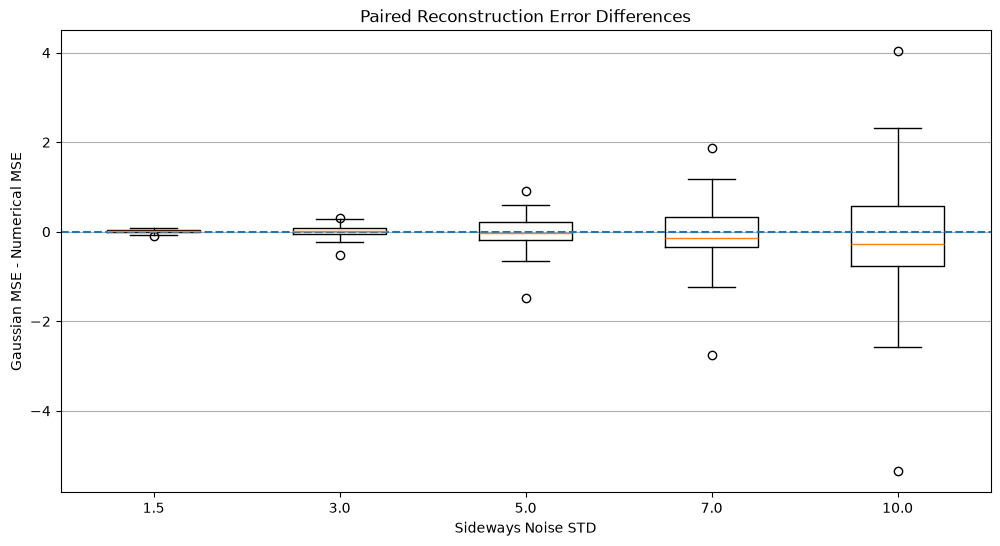

In [47]:
#visualising paired diff
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import wilcoxon

paired_differences = {}

for noise_std in noise_levels:

    kernel = trained_models[noise_std]["kernel"]
    window = trained_models[noise_std]["window"]

    gaussian_errors = []
    numerical_errors = []

    for seed in test_seeds:

        _, clean, noisy, regimes = generate_signal(
            seed=seed,
            sideways_noise_std=noise_std
        )

        mask = regimes == "sideways"

        image = signal_to_image(noisy)

        filtered = apply_gaussian_filter(
            image, kernel_size=kernel
        )

        gaussian_recovered = recover_signal(
            filtered, np.min(noisy), np.max(noisy)
        )

        numerical_recovered = moving_average(
            noisy, window_size=window
        )

        gaussian_errors.append(
            np.mean((gaussian_recovered[mask] - clean[mask]) ** 2)
        )

        numerical_errors.append(
            np.mean((numerical_recovered[mask] - clean[mask]) ** 2)
        )

    differences = np.array(gaussian_errors) - np.array(numerical_errors)

    paired_differences[noise_std] = differences

# Plot
plt.figure(figsize=(12, 6))

plt.boxplot(
    [paired_differences[n] for n in noise_levels],
    tick_labels=noise_levels
)

plt.axhline(0, linestyle="--")
plt.xlabel("Sideways Noise STD")
plt.ylabel("Gaussian MSE - Numerical MSE")
plt.title("Paired Reconstruction Error Differences")
plt.grid(axis="y")
plt.show()

Gaussian performs substantially better on some signals.
Numerical performs substantially better on others.
The average Gaussian advantage doesn't mean Gaussian wins on every individual signal.

In [49]:
for noise_std in noise_levels:

    differences = paired_differences[noise_std]

    gaussian_wins = np.sum(differences < 0)
    numerical_wins = np.sum(differences > 0)
    ties = np.sum(differences == 0)

    print(f"\nNoise STD: {noise_std}")
    print(f"Gaussian wins: {gaussian_wins}/50")
    print(f"Numerical wins: {numerical_wins}/50")
    print(f"Ties: {ties}/50")
    print(f"Median difference: {np.median(differences):.5f}")


Noise STD: 1.5
Gaussian wins: 21/50
Numerical wins: 29/50
Ties: 0/50
Median difference: 0.01227

Noise STD: 3.0
Gaussian wins: 23/50
Numerical wins: 27/50
Ties: 0/50
Median difference: 0.02480

Noise STD: 5.0
Gaussian wins: 27/50
Numerical wins: 23/50
Ties: 0/50
Median difference: -0.02094

Noise STD: 7.0
Gaussian wins: 30/50
Numerical wins: 20/50
Ties: 0/50
Median difference: -0.14135

Noise STD: 10.0
Gaussian wins: 29/50
Numerical wins: 21/50
Ties: 0/50
Median difference: -0.27350


CURRENT CONCLUSIONS

The relative performance of image-based Gaussian filtering and numerical moving-average smoothing depends on noise intensity.
- Numerical smoothing performs better at lower noise levels.
- Gaussian image processing performs better at higher noise levels in our test set.
- Neither method dominates across all individual signals.
- Independent testing supports the observed trend, but statistical evidence remains inconclusive.

In [52]:
from pathlib import Path

ROOT = Path("/home/Zoro/Projects/QuantForge")

FIGURES_DIR = ROOT / "report" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
from pathlib import Path
import nbformat
import base64

# Project paths
ROOT = Path.home() / "Projects" / "QuantForge"
NOTEBOOK_PATH = ROOT / "experiments" / "benchmark.ipynb"

PLOTS_DIR = ROOT / "outputs" / "plots"
REPORT_DIR = ROOT / "report" / "figures"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Read the saved notebook
notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)

saved_count = 0

# Extract all previously generated PNG plots
for cell_index, cell in enumerate(notebook.cells):

    if cell.cell_type != "code":
        continue

    for output_index, output in enumerate(cell.get("outputs", [])):

        data = output.get("data", {})

        if "image/png" not in data:
            continue

        image_data = data["image/png"]

        # Handle both base64 strings and multiline base64 output
        if isinstance(image_data, list):
            image_data = "".join(image_data)

        image_bytes = base64.b64decode(image_data)

        filename = (
            f"cell_{cell_index:03d}_plot_{output_index:02d}.png"
        )

        output_path = PLOTS_DIR / filename
        output_path.write_bytes(image_bytes)

        saved_count += 1
        print(f"Saved: {filename}")

print(f"\nTotal plots extracted: {saved_count}")
print(f"Location: {PLOTS_DIR}")
print(FIGURES_DIR)


Saved: cell_002_plot_00.png
Saved: cell_009_plot_00.png
Saved: cell_015_plot_00.png
Saved: cell_018_plot_00.png
Saved: cell_020_plot_00.png
Saved: cell_033_plot_00.png
Saved: cell_033_plot_01.png
Saved: cell_033_plot_02.png
Saved: cell_044_plot_00.png

Total plots extracted: 9
Location: /home/Zoro/Projects/QuantForge/outputs/plots
/home/Zoro/Projects/QuantForge/report/figures
